Предсказание оттока клиентов
customer_id — неиспользуемая переменная.
credit_score — используется в качестве входных данных.
country — используется в качестве входных данных.
gender — используется в качестве входных данных.
age — используется в качестве входных данных.
tenure — срок обслуживания клиента в банке.
balance — используется в качестве входных данных.
products_number — используется в качестве входных данных.
credit_card — используется в качестве входных данных.
active_member — используется в качестве входных данных.
estimated_salary — используется в качестве входных данных.
churn — целевая переменная: 1, если клиент покинул банк за определенный период, и 0, если нет.

Цель проекта: построить модель классификации для анализа оттока клиентов

Всего 10000 наблюдений

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.metrics import precision_recall_curve

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
bank = pd.read_csv('Bank_Customer_Churn_Prediction.csv')
bank.head(10)

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,15574012,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,15592531,822,France,Male,50,7,0.00,2,1,1,10062.80,0
7,15656148,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
8,15792365,501,France,Male,44,4,142051.07,2,0,1,74940.50,0
9,15592389,684,France,Male,27,2,134603.88,1,1,1,71725.73,0


Разведочный анализ данных (EDA — Exploratory Data Analysis)

In [4]:
bank.dtypes

customer_id           int64
credit_score          int64
country                 str
gender                  str
age                   int64
tenure                int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
dtype: object

In [5]:
bank.isna().sum()

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

In [6]:
bank.duplicated().sum()

np.int64(0)

In [7]:
bank.nunique()

customer_id         10000
credit_score          460
country                 3
gender                  2
age                    70
tenure                 11
balance              6382
products_number         4
credit_card             2
active_member           2
estimated_salary     9999
churn                   2
dtype: int64

In [8]:
bank.describe()

,customer_id,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [9]:
country_stats = bank.groupby('country')['churn'].describe()
country_stats

,count,mean,std,min,25%,50%,75%,max
country,,,,,,,,
France,5014.0,0.161548,0.368072,0.0,0.0,0.0,0.0,1.0
Germany,2509.0,0.324432,0.468256,0.0,0.0,0.0,1.0,1.0
Spain,2477.0,0.166734,0.372813,0.0,0.0,0.0,0.0,1.0


In [10]:
product_stats = bank.groupby('products_number')['churn'].describe()
product_stats

,count,mean,std,min,25%,50%,75%,max
products_number,,,,,,,,
1,5084.0,0.277144,0.447632,0.0,0.0,0.0,1.0,1.0
2,4590.0,0.075817,0.264734,0.0,0.0,0.0,0.0,1.0
3,266.0,0.827068,0.378902,0.0,1.0,1.0,1.0,1.0
4,60.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0


In [11]:
amount_churn = bank['churn'].mean()*100
amount_churn

np.float64(20.369999999999997)

20.37% клиентов покинули банк (2037 человек)

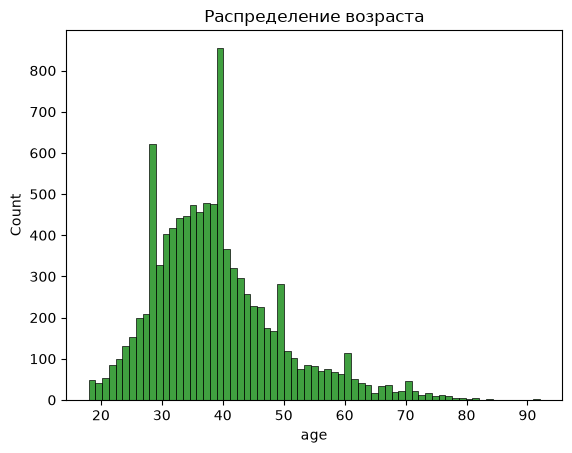

In [12]:
sns.histplot(data=bank, x='age', bins='auto', color = 'green')
plt.title('Распределение возраста')
plt.show()

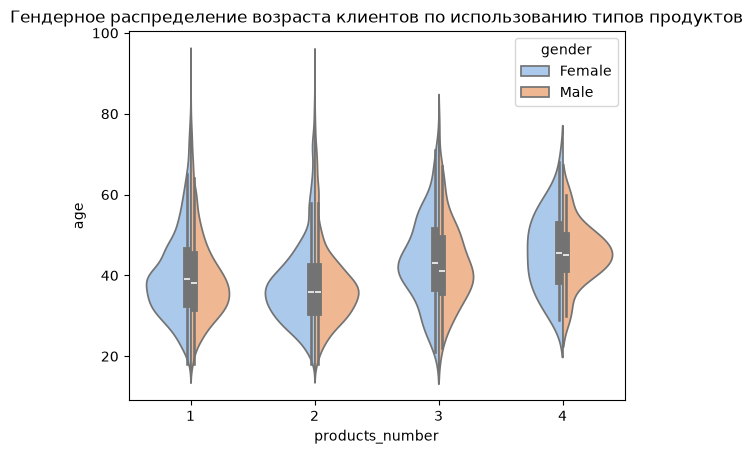

In [13]:
sns.violinplot(data=bank, x='products_number', y='age', hue = 'gender', split=True, palette='pastel')
plt.title('Гендерное распределение возраста клиентов по использованию типов продуктов')
plt.show()

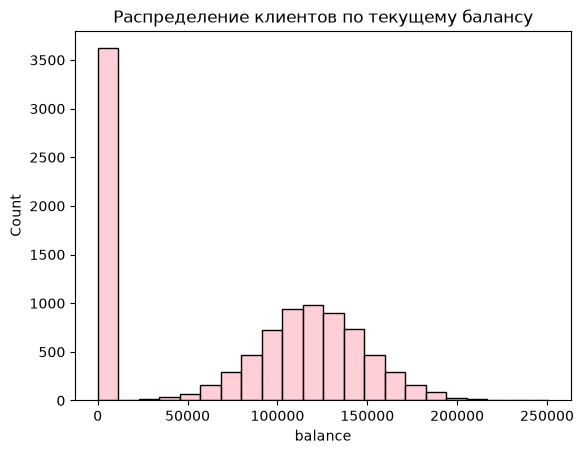

In [14]:
sns.histplot(data=bank, x='balance', bins='auto', color = 'pink')
plt.title('Распределение клиентов по текущему балансу')
plt.show()

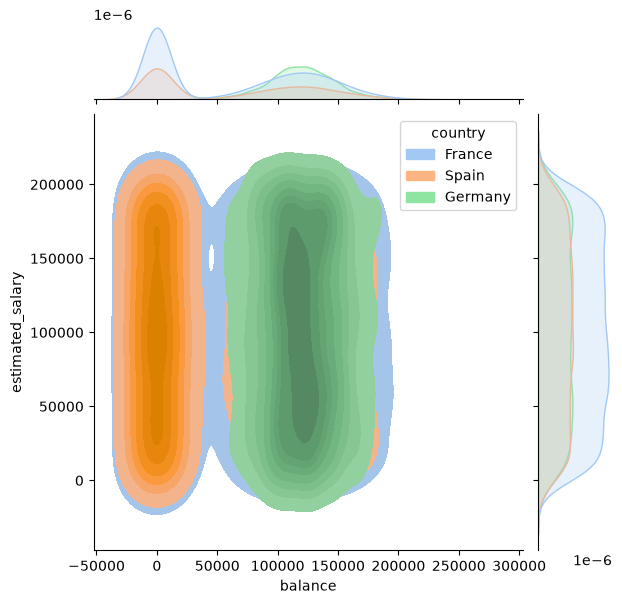

In [15]:
# Распределение с учетом стран клиентов по текущему балансу и текущей зарплате
sns.jointplot(data=bank, x='balance', y='estimated_salary', hue = 'country', kind='kde', fill=True, palette='pastel')
plt.show()

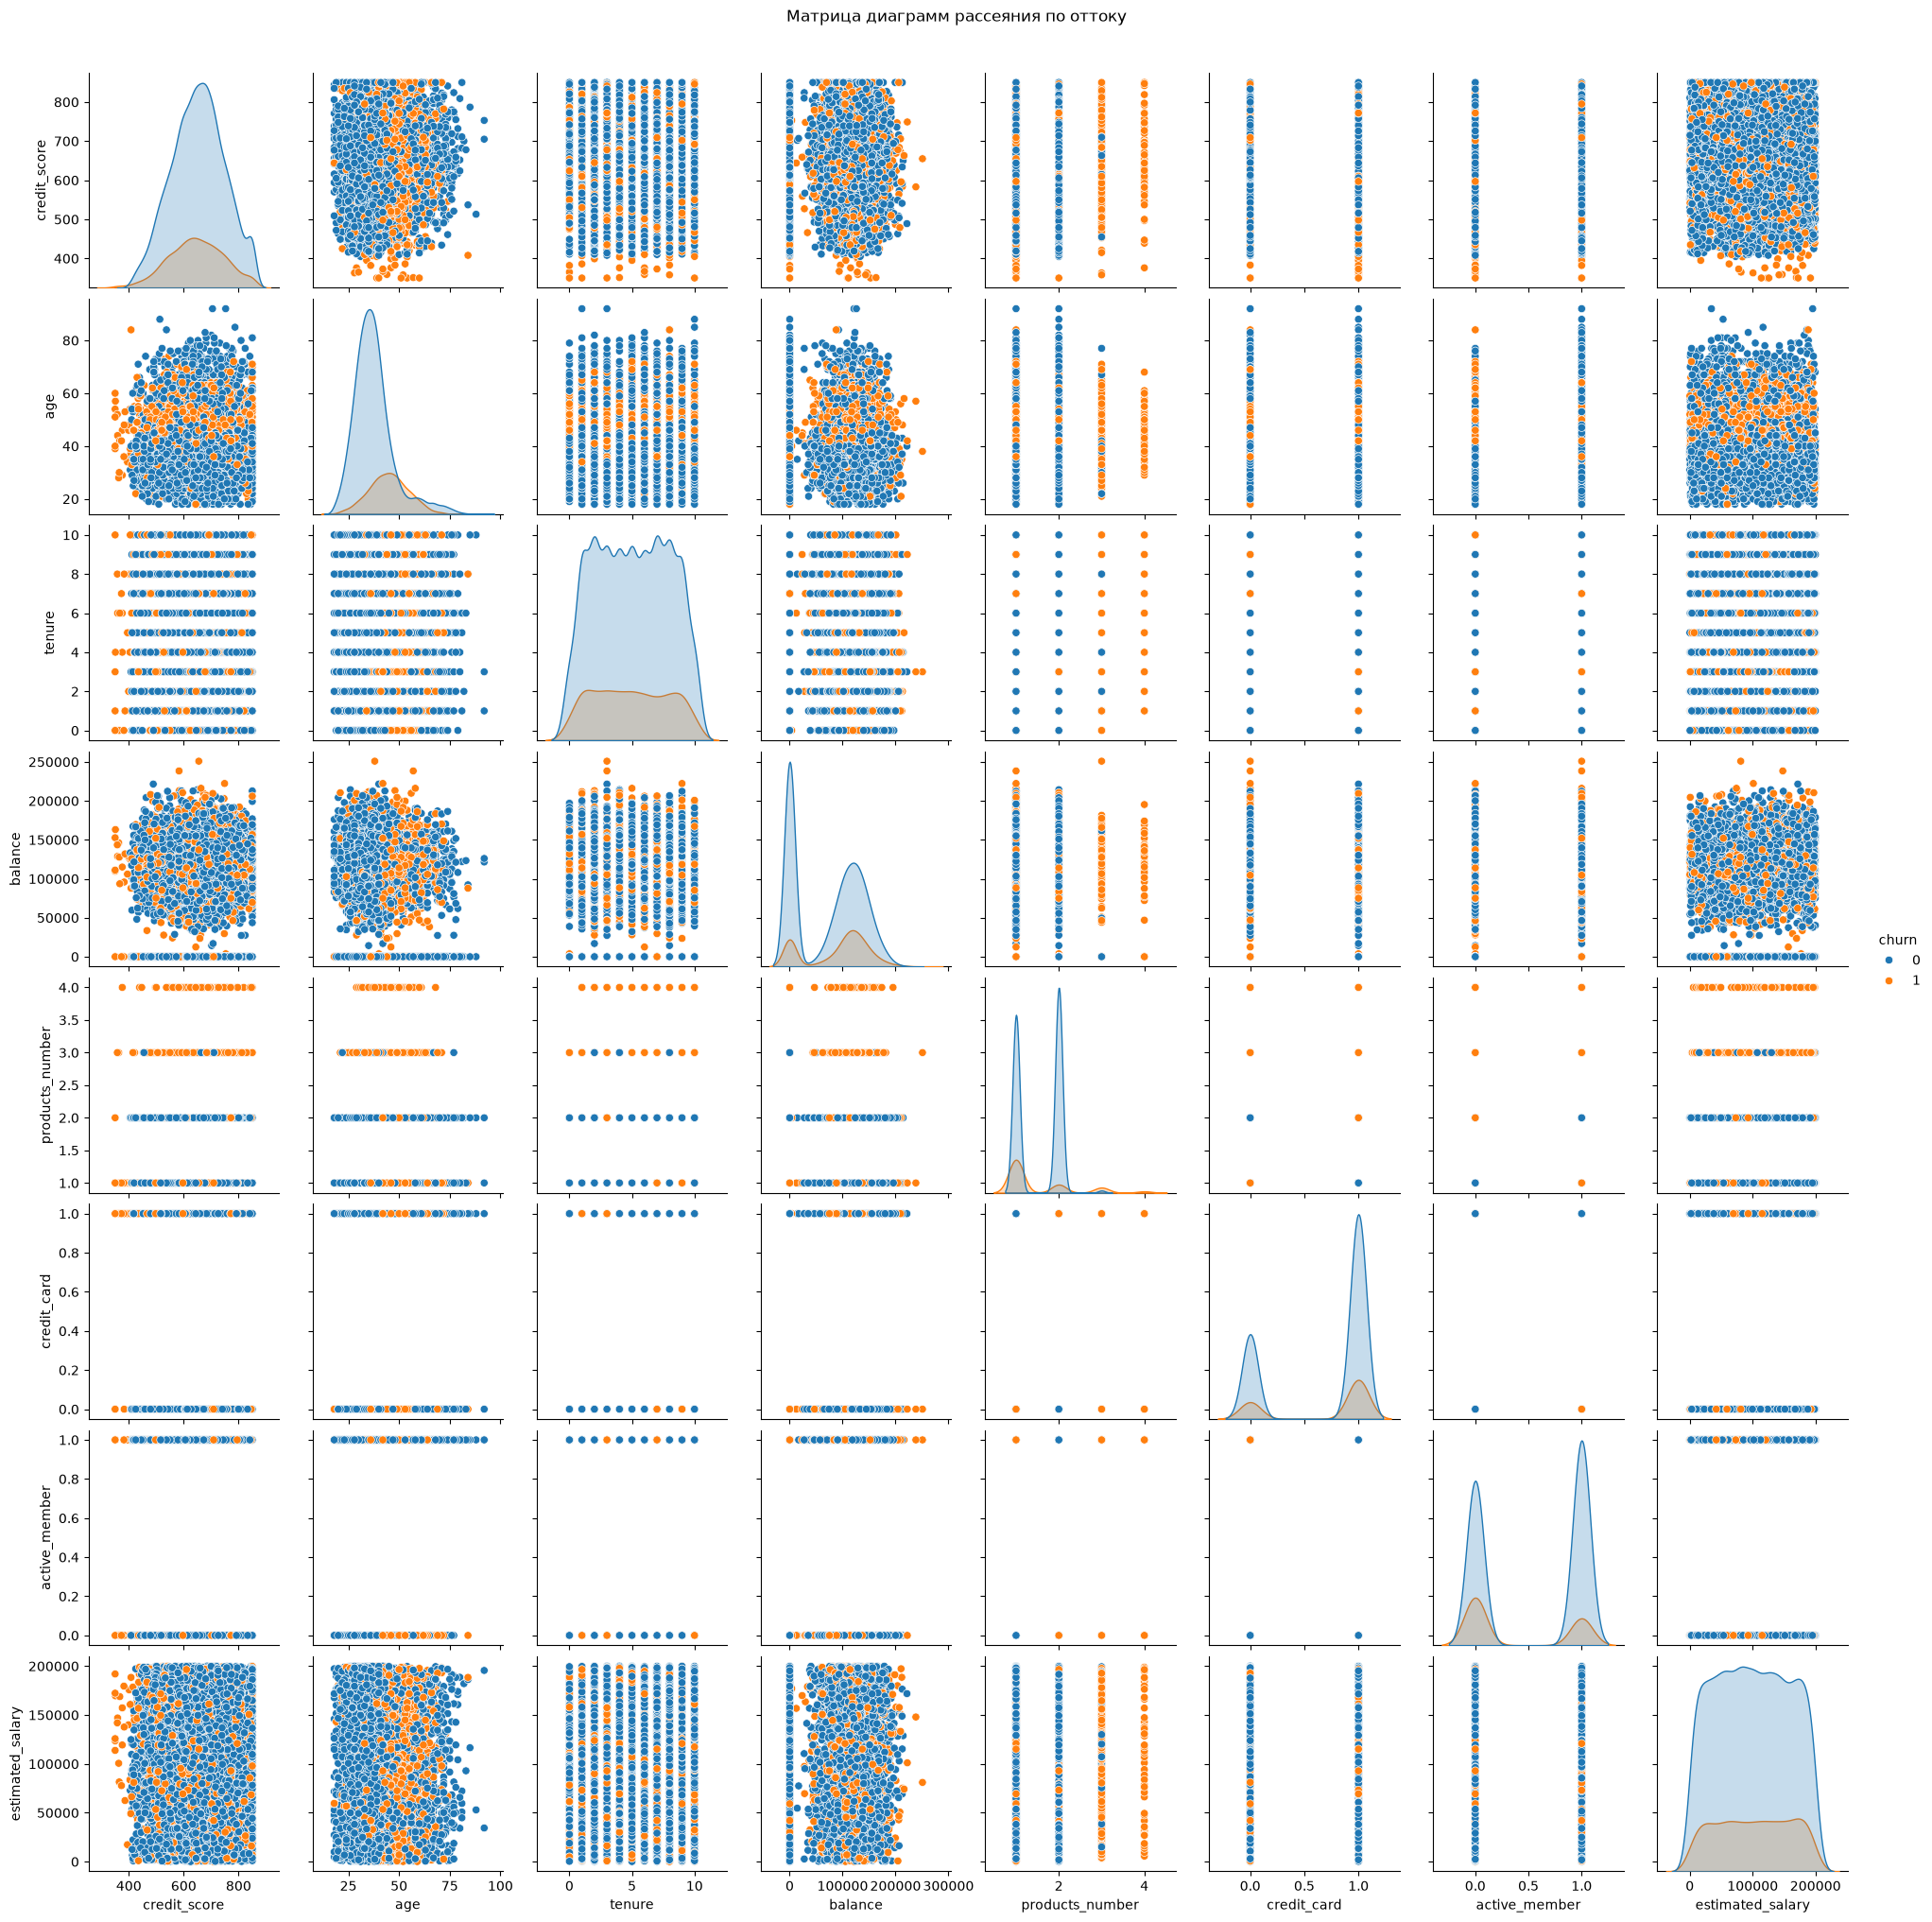

In [16]:
g = sns.pairplot(bank.drop(columns='customer_id'), hue='churn')
g.fig.suptitle('Матрица диаграмм рассеяния по оттоку', y=1.02)
plt.show()

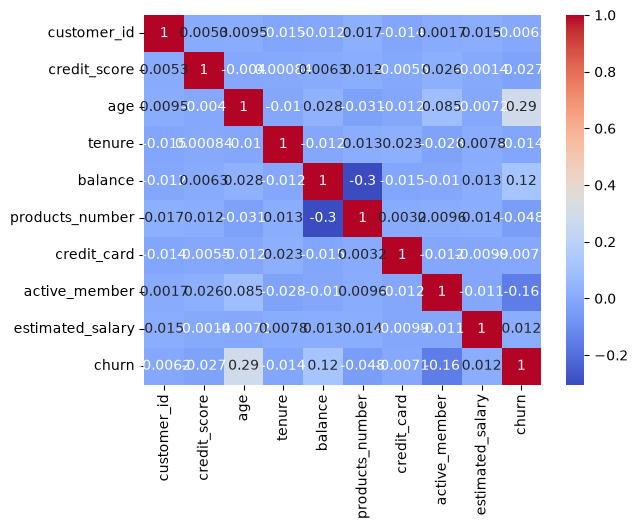

In [17]:
# Корреляционный анализ (Feature Correlation)
matrix = bank.corr(numeric_only=True)
sns.heatmap(matrix, annot=True, cmap='coolwarm')
plt.show()

In [18]:
# Выделение признаков
X = bank.drop(columns = ['customer_id', 'churn'])
y = bank['churn']

In [19]:
cat_features = ['country', 'gender']

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [21]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [22]:
model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    cat_features=cat_features,
    random_seed=42,
    verbose=100)
model.fit(X_tr, y_tr)

0:	learn: 0.6515027	total: 67.1ms	remaining: 33.5s
100:	learn: 0.3156013	total: 325ms	remaining: 1.28s
200:	learn: 0.2939056	total: 569ms	remaining: 846ms
300:	learn: 0.2716117	total: 820ms	remaining: 542ms
400:	learn: 0.2520171	total: 1.08s	remaining: 266ms
499:	learn: 0.2341788	total: 1.33s	remaining: 0us


CatBoostClassifier(cat_features=['country', 'gender'], depth=6, iterations=500, learning_rate=0.05, random_seed=42, verbose=100)

In [23]:
y_pred = model.predict(X_test)

In [24]:
importance = model.get_feature_importance()
feature_names = X.columns

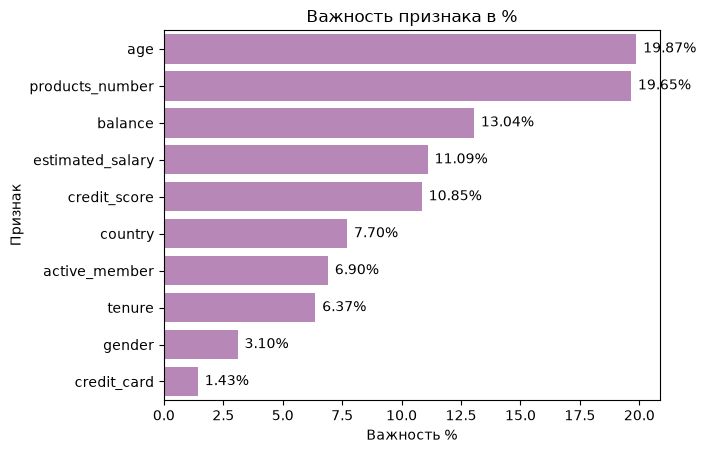

In [25]:
bank_importance = pd.DataFrame({
    'Признак': feature_names,
    'Важность %': importance
}).sort_values(by='Важность %', ascending=False)

ax = sns.barplot(data=bank_importance, x='Важность %', y='Признак', color = 'purple', alpha =0.5)
ax.bar_label(ax.containers[0], fmt='%.2f%%', fontsize=10, padding = 5)
plt.title('Важность признака в %')
plt.show()

Самыми важными признаками, которые влияют на отток клиентов, являются возраст, количество используемых продуктов и баланс

In [26]:
# Необходимо для расчета ROC-AUC
y_probability = model.predict_proba(X_test)[:,1]

In [27]:
print(classification_report(y_test, y_pred, target_names=['Остался (0)', 'Ушел (1)']))

              precision    recall  f1-score   support

 Остался (0)       0.88      0.96      0.92      1593
    Ушел (1)       0.78      0.49      0.60       407

    accuracy                           0.87      2000
   macro avg       0.83      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000



Recall составляет 0.47. Это значит, что модель находит только половину уходящих клиентов.
Подберем порог по предсказанным вероятностям

In [28]:
# Подбор порога для валидационных клиентов
val_proba = model.predict_proba(X_val)[:,1]
prec, rec, thr =  precision_recall_curve(y_val, val_proba) # считаем множество линий

In [29]:
f1 = 2 * prec * rec / (prec + rec + 1e-9) #+ 1e-9 - для защиты от деления на ноль

In [30]:
best_thr = thr[f1[:-1].argmax()] # Выбираем лучшую оценку
y_pred_new = (y_probability >= best_thr).astype(int)

In [31]:
print(best_thr)

0.3350437562249451


In [32]:
print(classification_report(y_test, y_pred_new, target_names=['Остался (0)', 'Ушел (1)']))

              precision    recall  f1-score   support

 Остался (0)       0.90      0.91      0.91      1593
    Ушел (1)       0.64      0.62      0.63       407

    accuracy                           0.85      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.85      0.85      0.85      2000



Recall вырос с 0,49 до 0,62
Precision ухудшился с 0,78 до 0,64
f1-score вырос с 0,60 до 0,63

In [33]:
# Расчет ROC-AUC
roc_auc = roc_auc_score(y_test, y_probability)
roc_auc 

0.8608130472537253

Метрика ROC-AUC составляет 0.860
Модель заметно лучше случайного угадывания (0,5)